# Eksperimen Machine Learning: Prediksi Gagal Bayar Kartu Kredit

**Domain:** Finance / credit risk. **Sumber data:** ISLR `Default` (data simulasi 10.000 nasabah; bukan data transaksi atau nasabah riil). **Target:** `default` (Yes/No).

Notebook ini disusun memakai bagian template eksperimen: pengenalan dataset, impor library, pemuatan data, EDA, dan preprocessing. Data mentah disertakan di folder proyek. Sumber data: https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/ISLR/Default.csv .

## 1. Perkenalan Dataset
Dataset berisi status gagal bayar, status mahasiswa, saldo kartu kredit rata-rata setelah pembayaran bulanan, dan pendapatan. Ini dataset simulasi untuk pembelajaran, bukan dasar keputusan kredit nyata.

## 2. Import Library

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, RocCurveDisplay)
import joblib
R = Path.cwd()
# Notebook dijalankan dari direktori eksperimen.
DATA = R / 'credit_default_raw.csv'
OUT = R.parent / 'Membangun_model' / 'model_artifacts'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
print('Data:', DATA, '| ditemukan:', DATA.exists())

Data: /home/user/.local/share/mesa/.mnt.fuse.1/lindy/agent-user-6af583b3ba350467dbdcaa4f-6af583b5ba350467dbdcaa55/Dicoding/Proyek_Finance_Credit_Risk/Eksperimen_SML_Yahya_Putra_Pradana/credit_default_raw.csv | ditemukan: True


## 3. Memuat Dataset

In [2]:
df_raw = pd.read_csv(DATA)
print('Ukuran:', df_raw.shape)
print('Kolom:', df_raw.columns.tolist())
print('Missing values:', int(df_raw.isna().sum().sum()))
print('Baris duplikat:', int(df_raw.duplicated().sum()))
display(df_raw.head())
display(df_raw.describe(include='all').T)

Ukuran: (10000, 5)
Kolom: ['rownames', 'default', 'student', 'balance', 'income']
Missing values: 0
Baris duplikat: 0


,rownames,default,student,balance,income
0,1,No,No,729.526495,44361.625074
1,2,No,Yes,817.180407,12106.134700
2,3,No,No,1073.549164,31767.138947
3,4,No,No,529.250605,35704.493935
4,5,No,No,785.655883,38463.495879


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rownames,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
default,10000,2,No,9667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
student,10000,2,No,7056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,10000.0,NaN,NaN,NaN,835.374886,483.714985,0.0,481.731105,823.636973,1166.308386,2654.322576
income,10000.0,NaN,NaN,NaN,33516.981876,13336.639563,771.967729,21340.462903,34552.644802,43807.729272,73554.233495


## 4. Exploratory Data Analysis (EDA)
Periksa ketidakseimbangan target dan pola saldo/pendapatan; visualisasi bersifat deskriptif, bukan bukti kausal.

Distribusi target:


,jumlah
default,
No,9667
Yes,333


Proporsi default: 3.33%


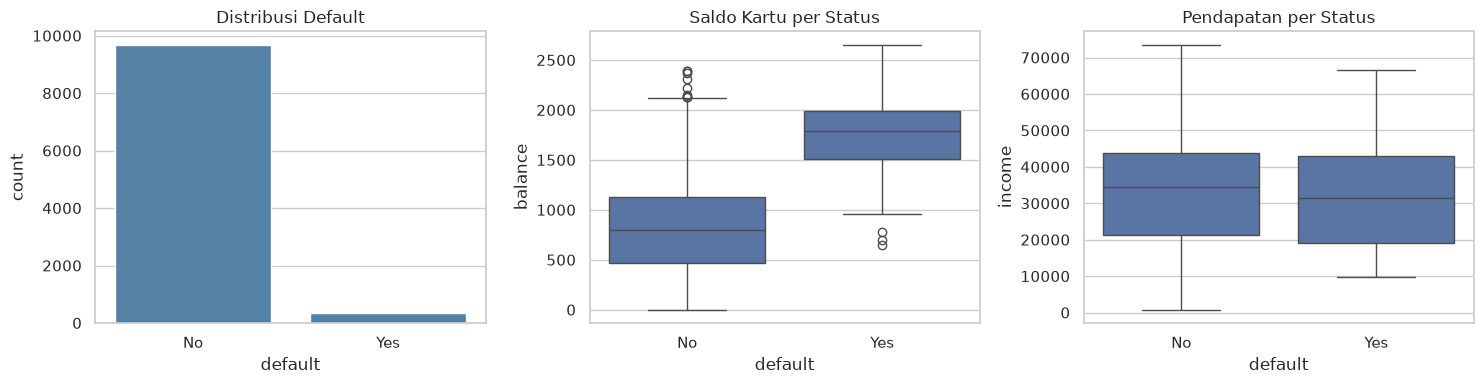

In [3]:
print('Distribusi target:')
display(df_raw['default'].value_counts().rename_axis('default').to_frame('jumlah'))
print('Proporsi default:', f"{(df_raw['default'].eq('Yes').mean()):.2%}")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df_raw, x='default', ax=axes[0], color='steelblue')
axes[0].set_title('Distribusi Default')
sns.boxplot(data=df_raw, x='default', y='balance', ax=axes[1])
axes[1].set_title('Saldo Kartu per Status')
sns.boxplot(data=df_raw, x='default', y='income', ax=axes[2])
axes[2].set_title('Pendapatan per Status')
plt.tight_layout(); plt.show()

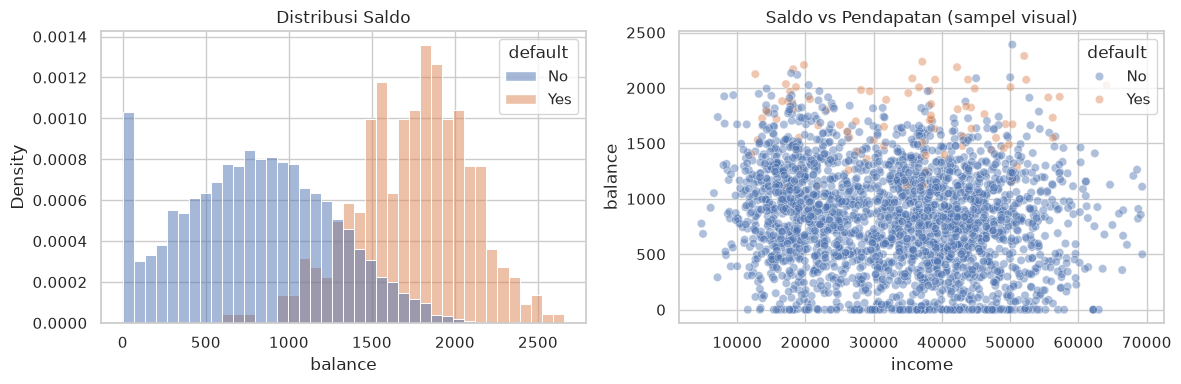

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_raw, x='balance', hue='default', bins=40, stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('Distribusi Saldo')
sns.scatterplot(data=df_raw.sample(min(2500, len(df_raw)), random_state=42), x='income', y='balance', hue='default', alpha=.45, ax=axes[1])
axes[1].set_title('Saldo vs Pendapatan (sampel visual)')
plt.tight_layout(); plt.show()

## 5. Data Preprocessing
Hapus kolom indeks `rownames` (bukan fitur), buang duplikat, validasi nilai, petakan target menjadi 0/1, lakukan stratified train/test split. One-hot encoding dan scaling berada dalam pipeline agar hanya dipelajari dari training split.

In [5]:
df = df_raw.drop(columns=[c for c in ['rownames', 'Unnamed: 0'] if c in df_raw.columns]).drop_duplicates().copy()
df['default'] = df['default'].map({'No': 0, 'Yes': 1})
df['student'] = df['student'].astype(str).str.strip().str.lower()
for c in ['balance', 'income']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
print('Missing setelah parsing:', int(df.isna().sum().sum()))
df = df.dropna(subset=['default','student','balance','income']).reset_index(drop=True)
X = df[['student','balance','income']]
y = df['default'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
print('Shape bersih:', df.shape, '| fitur:', X.shape[1])
print('Train/test:', X_train.shape, X_test.shape, '| rate target train/test:', round(y_train.mean(),4), round(y_test.mean(),4))
print('Baris terbuang:', len(df_raw)-len(df))

Missing setelah parsing: 0
Shape bersih: (10000, 4) | fitur: 3
Train/test: (8000, 3) (2000, 3) | rate target train/test: 0.0332 0.0335
Baris terbuang: 0


## 6. Modeling dan Evaluasi
Membandingkan Logistic Regression dengan Random Forest pada holdout yang sama. Karena target jarang, laporkan precision, recall, F1, ROC-AUC, dan Average Precision selain accuracy. Holdout hanya untuk evaluasi; tuning lanjutan dilakukan terpisah.

In [6]:
numeric = ['balance','income']; categorical = ['student']
preprocessor = ColumnTransformer([
 ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
 ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical),
])
models = {
 'Logistic Regression': Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))]),
 'Random Forest': Pipeline([('prep', preprocessor), ('model', RandomForestClassifier(n_estimators=250, class_weight='balanced', min_samples_leaf=3, random_state=42, n_jobs=-1))]),
}
results = {}; fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train); fitted[name] = model
    pred = model.predict(X_test); prob = model.predict_proba(X_test)[:,1]
    results[name] = {'accuracy':accuracy_score(y_test,pred), 'precision':precision_score(y_test,pred,zero_division=0),
       'recall':recall_score(y_test,pred,zero_division=0), 'f1':f1_score(y_test,pred,zero_division=0),
       'roc_auc':roc_auc_score(y_test,prob), 'average_precision':average_precision_score(y_test,prob)}
print(pd.DataFrame(results).T.round(4).to_string())
for name, model in fitted.items():
 print('\n',name,'\n',classification_report(y_test,model.predict(X_test),zero_division=0))

                     accuracy  precision  recall      f1  roc_auc  average_precision
Logistic Regression     0.855     0.1730  0.8806  0.2892   0.9487             0.5236
Random Forest           0.963     0.4533  0.5075  0.4789   0.9034             0.4662

 Logistic Regression 
               precision    recall  f1-score   support

           0       1.00      0.85      0.92      1933
           1       0.17      0.88      0.29        67

    accuracy                           0.85      2000
   macro avg       0.58      0.87      0.60      2000
weighted avg       0.97      0.85      0.90      2000


 Random Forest 
               precision    recall  f1-score   support

           0       0.98      0.98      0.98      1933
           1       0.45      0.51      0.48        67

    accuracy                           0.96      2000
   macro avg       0.72      0.74      0.73      2000
weighted avg       0.97      0.96      0.96      2000



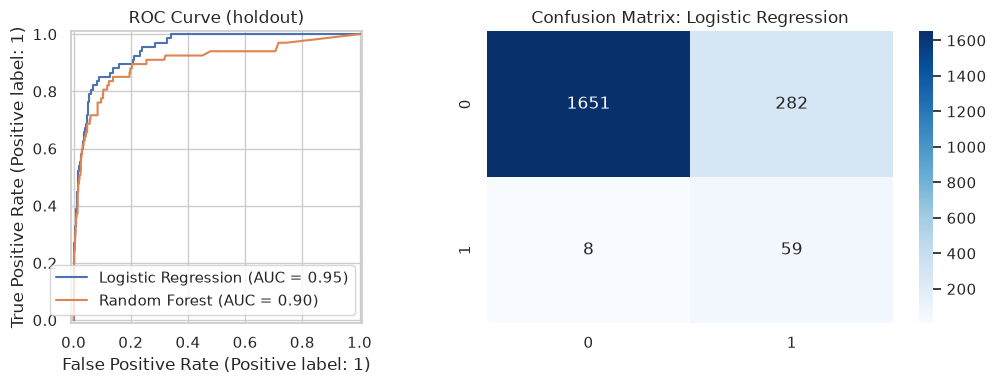

Baseline model dan metrik tersimpan di /home/user/.local/share/mesa/.mnt.fuse.1/lindy/agent-user-6af583b3ba350467dbdcaa4f-6af583b5ba350467dbdcaa55/Dicoding/Proyek_Finance_Credit_Risk/Membangun_model/model_artifacts


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
axes[0].set_title('ROC Curve (holdout)')
cm = confusion_matrix(y_test, fitted['Logistic Regression'].predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Confusion Matrix: Logistic Regression')
plt.tight_layout(); plt.show()
joblib.dump(fitted['Logistic Regression'], OUT/'credit_default_model.joblib')
metrics = pd.DataFrame(results).T
metrics.to_csv(OUT/'experiment_metrics.csv', index=True)
print('Baseline model dan metrik tersimpan di', OUT)

## 7. Kesimpulan Awal
Gunakan tabel metrik di atas untuk membaca trade-off false positive/false negative. Model ini hanya baseline akademik untuk data simulasi dan tidak boleh dipakai untuk keputusan kredit nyata. Sebelum penerapan dibutuhkan validasi out-of-time, kalibrasi probabilitas, uji fairness, dan kebijakan persetujuan manusia.